In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volumen_binance,trades_binance,var_diaria_binance,rango_dia_binance,volatilidad_7_binance,...,EMA_200_dxy,RSI_dxy,MACD_dxy,MACD_signal_dxy,MACD_hist_dxy,precio_medio,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-01-30,23743.37,23800.51,22500.00,22826.15,302405.90121,7790224.0,-3.858725,1300.51,343.123213,...,105.562407,43.560953,-0.415354,-0.514791,0.099436,NaN,-0.278759,-1,3.517106,1
1,2023-01-31,22827.38,23320.00,22714.77,23125.13,264649.34909,6798411.0,1.309814,605.23,288.912363,...,105.527955,40.489557,-0.387432,-0.489319,0.101887,NaN,0.498722,1,1.471084,1
2,2023-02-01,23125.13,23812.66,22760.23,23732.66,310790.42271,7863213.0,2.627142,1052.43,366.108175,...,105.485090,29.528127,-0.431340,-0.477723,0.046383,NaN,-3.243041,-1,-5.807693,-1
3,2023-02-02,23731.41,24255.00,23363.27,23488.94,364177.20751,9102300.0,-1.026939,891.73,365.258424,...,105.447924,40.054093,-0.418546,-0.465888,0.047342,NaN,-7.205902,-1,-4.863438,-1
4,2023-02-03,23489.33,23715.70,23204.62,23431.90,332571.02904,8007846.0,-0.242838,511.08,355.338896,...,105.422771,55.762488,-0.310419,-0.434794,0.124375,NaN,-7.710472,-1,-4.274771,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
797,2025-04-06,83537.99,83817.63,77153.83,78430.00,27942.71436,3948493.0,-6.114571,6663.80,2109.166708,...,106.107292,32.293625,-0.237004,-0.121354,-0.115650,83792.490667,NaN,0,NaN,0
798,2025-04-07,78430.00,81243.58,74508.00,79163.24,78387.53089,9736596.0,0.934897,6735.58,2514.023005,...,106.107292,32.293625,-0.237004,-0.121354,-0.115650,83557.183667,NaN,0,NaN,0
799,2025-04-08,79163.24,80867.99,76239.90,76322.42,35317.32063,5512751.0,-3.588560,4628.09,2995.753309,...,106.107292,32.293625,-0.237004,-0.121354,-0.115650,83410.118667,NaN,0,NaN,0
800,2025-04-09,76322.42,78318.46,74620.00,77824.01,37352.21586,5102765.0,1.967430,3698.46,3124.830182,...,106.107292,32.293625,-0.237004,-0.121354,-0.115650,83384.390333,NaN,0,NaN,0


# Visualización de la variable respuesta (7 días)

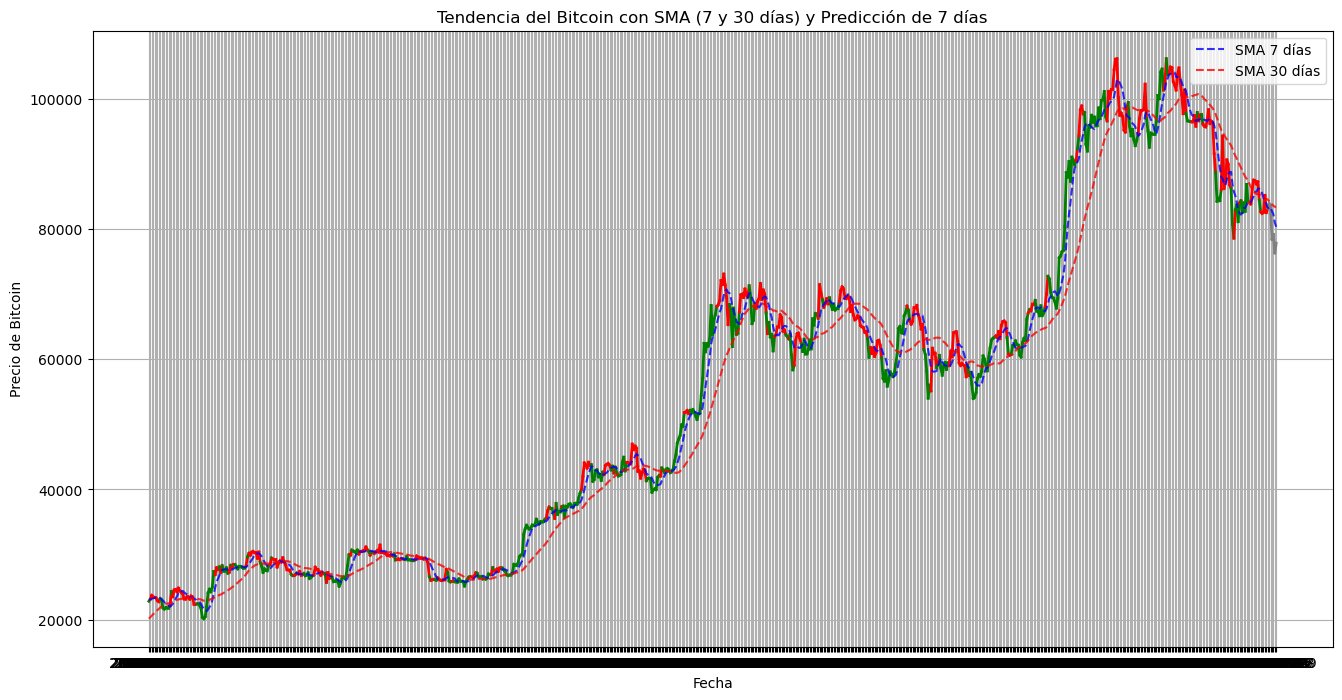

In [3]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_7_binance'], label="SMA 7 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_30_binance'], label="SMA 30 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (7 y 30 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Correlacion con variable respuesta

In [4]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volumen_binance', 'trades_binance',
                 'close_sp500', 'high_sp500', 'low_sp500', 'open_sp500', 'volume_sp500',
                 'close_nasdaq', 'high_nasdaq', 'low_nasdaq', 'open_nasdaq', 'volume_nasdaq',
                 'close_dxy', 'high_dxy', 'low_dxy', 'open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

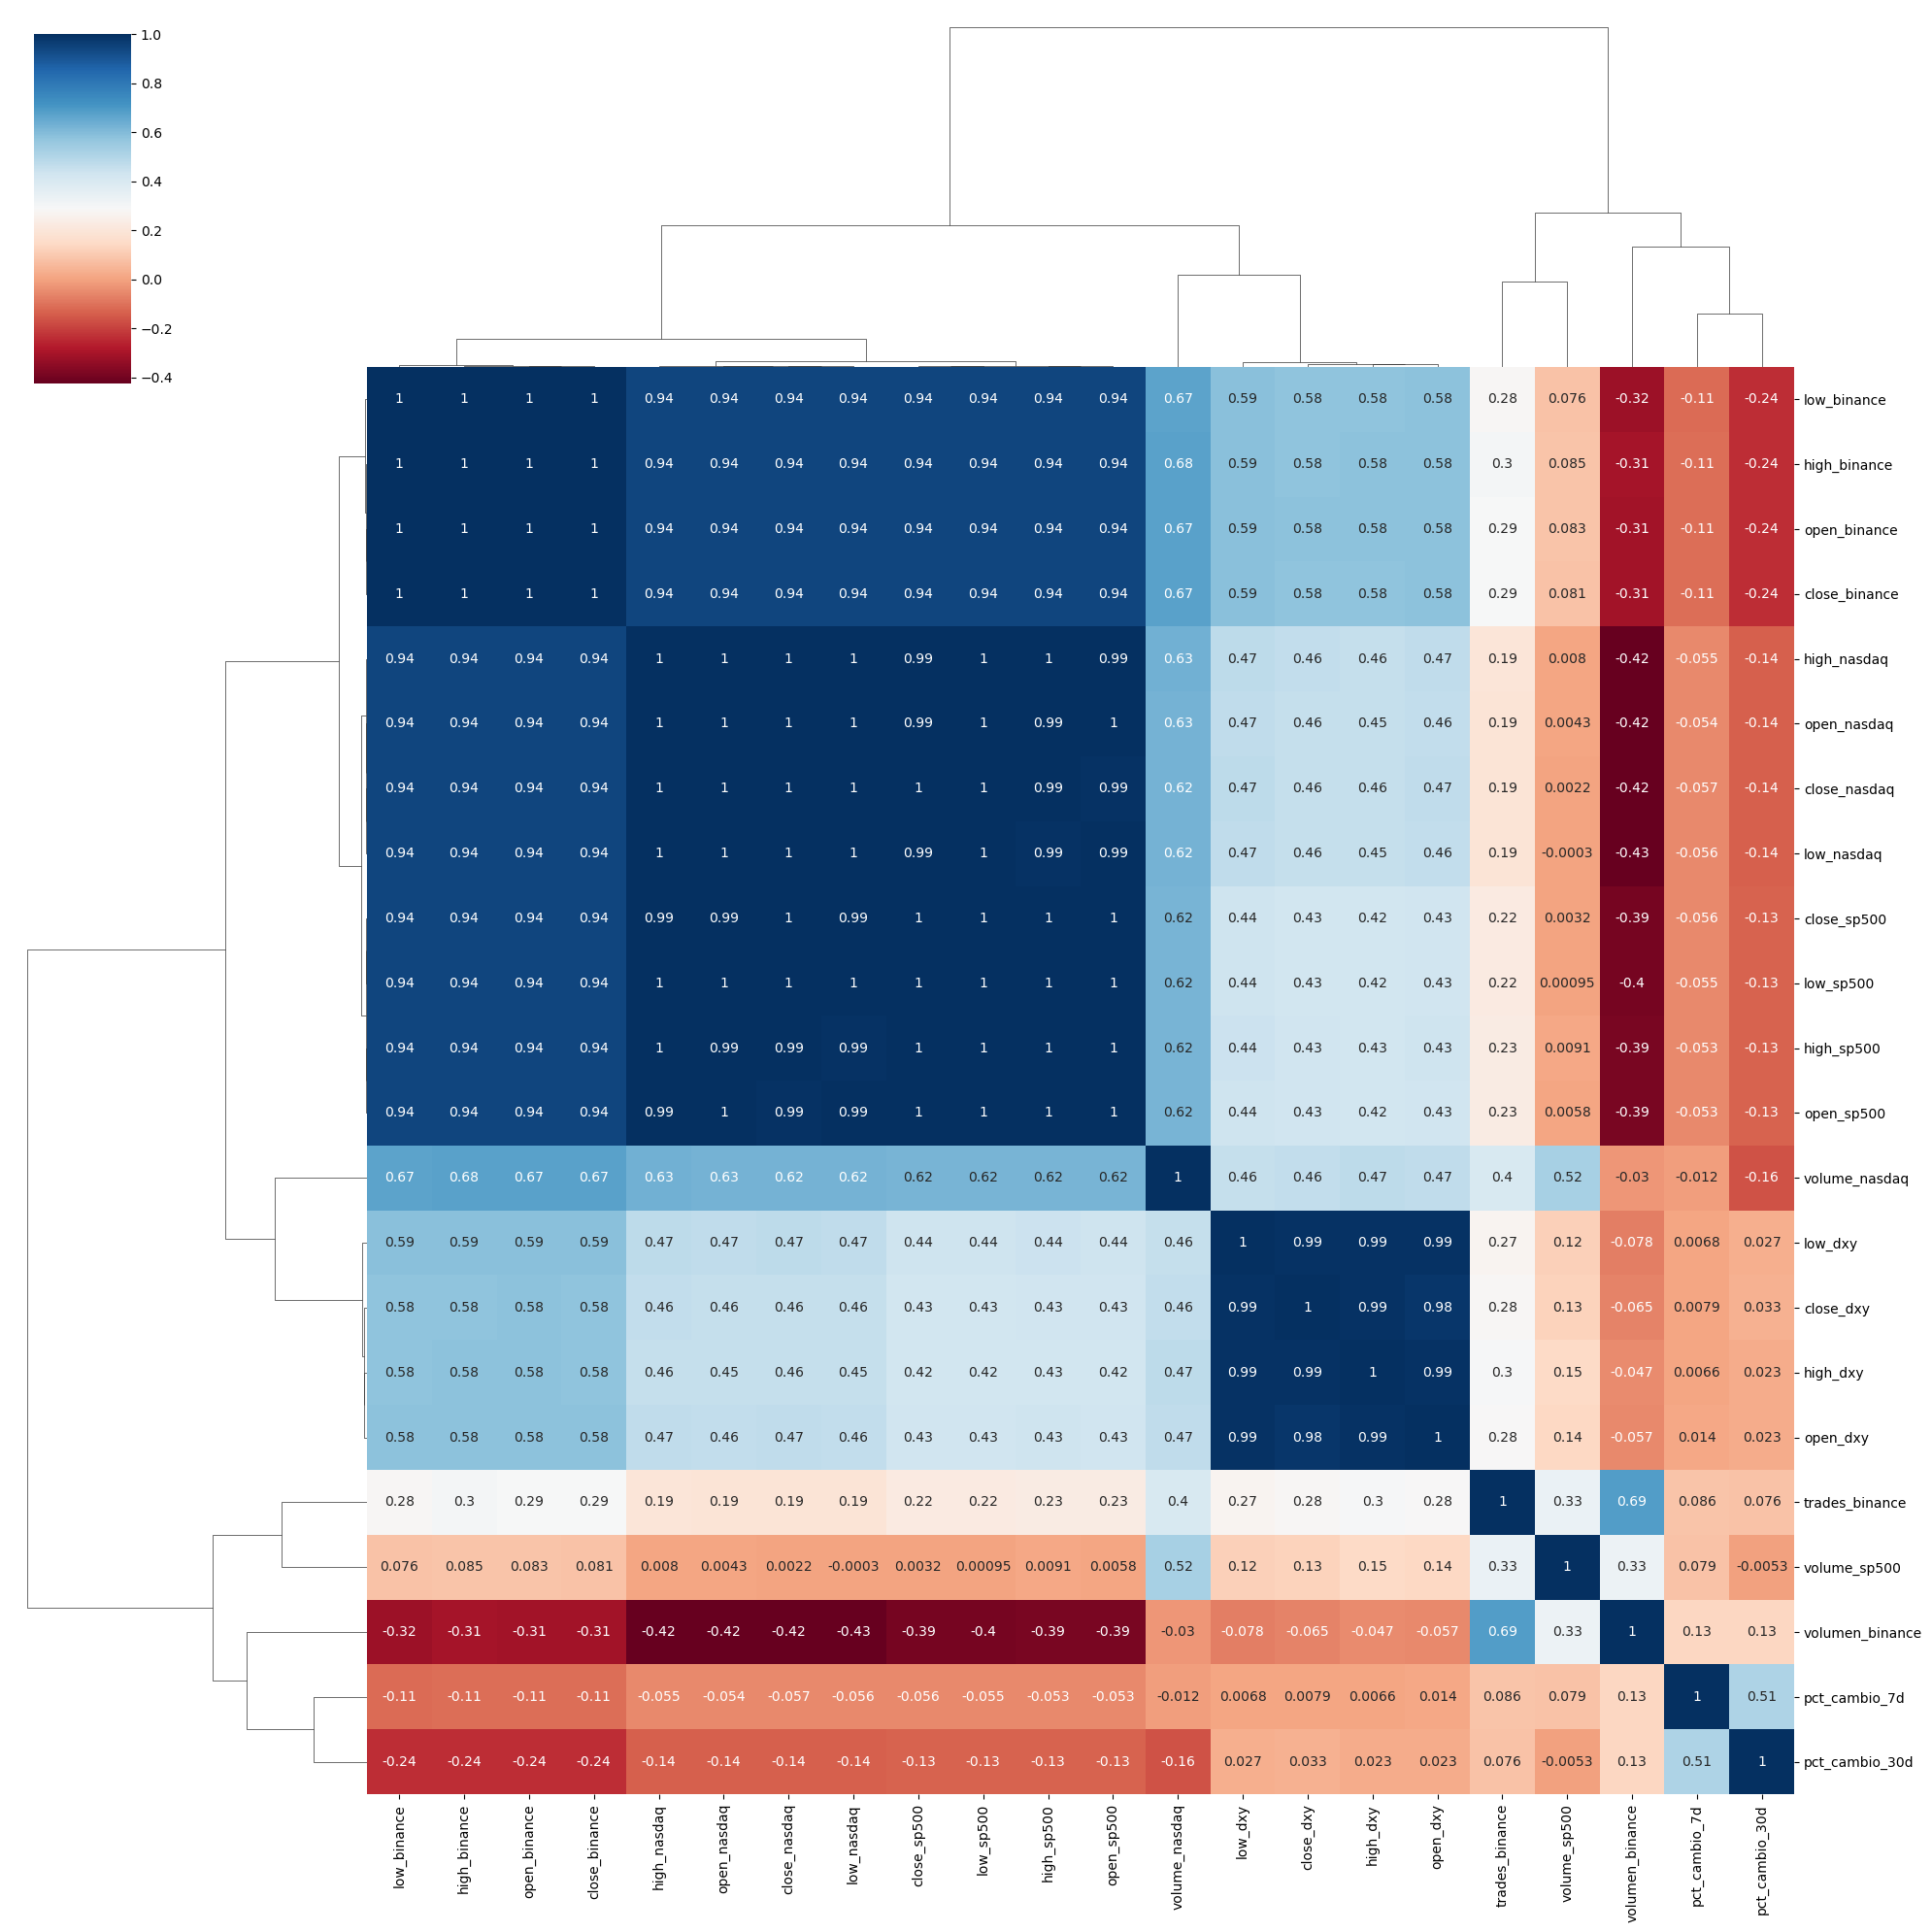

In [5]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()